In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [15]:
#Loading the data and getting information out of the data
data = pd.read_csv('AusApparalSales4thQrt2020.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


In [12]:
# 1st 10 records of the DataFrame
data.head(10)

,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500
5,1-Oct-2020,Afternoon,WA,Men,10,25000
6,1-Oct-2020,Afternoon,WA,Women,3,7500
7,1-Oct-2020,Afternoon,WA,Seniors,11,27500
8,1-Oct-2020,Evening,WA,Kids,15,37500
9,1-Oct-2020,Evening,WA,Men,15,37500


First, let's inspect the data manually to identify missing or incorrect information using the functions `isna()` and `notna()`. We will count the total number of missing values for each column and the overall total.

In [4]:
# Check for missing values in each column
missing_values_per_column = data.isna().sum()
print("Missing values per column:")
print(missing_values_per_column)

print("\nTotal missing values in the dataset:")
print(data.isnull().sum().sum())

Missing values per column:
Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Total missing values in the dataset:
0


For data normalization, we will focus on the numerical columns: `Unit` and `Sales`. We will use `MinMaxScaler` from `sklearn.preprocessing` to scale these features to a range between 0 and 1.

In [17]:
from sklearn.preprocessing import MinMaxScaler

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Select the numerical columns to normalize
numerical_cols = ['Unit', 'Sales']

# Apply Min-Max Normalization to the selected columns
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])

print("Data after Min-Max Normalization for 'Unit' and 'Sales' columns:")
data.head()

Data after Min-Max Normalization for 'Unit' and 'Sales' columns:


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,0.095238,0.095238
1,1-Oct-2020,Morning,WA,Men,0.095238,0.095238
2,1-Oct-2020,Morning,WA,Women,0.031746,0.031746
3,1-Oct-2020,Morning,WA,Seniors,0.206349,0.206349
4,1-Oct-2020,Afternoon,WA,Kids,0.015873,0.015873


Let's group the data by the 'Group' column and calculate the sum of 'Sales' for each group. This will show the total normalized sales for each customer segment.

In [19]:
grouped_sales = data.groupby('Group')['Sales'].sum().reset_index()
print("Total normalized sales by Group:")
display(grouped_sales)

Total normalized sales by Group:


,Group,Sales
0,Kids,480.142857
1,Men,484.444444
2,Seniors,473.571429
3,Women,482.492063


In [ ]:
# So here GroupBy() function gave the conclusion that Men and Seniors are the two in the group which accounts for maximum and minimum sales

Let's perform descriptive statistical analysis on the `Sales` and `Unit` columns, calculating their mean, median, mode, and standard deviation.

In [21]:
print("Descriptive statistics for 'Sales' column:")
data['Sales'].describe() # Descriptive statistics for 'Sales' column

Descriptive statistics for 'Sales' column:


,Sales
count,7560.000000
mean,0.254054
std,0.204784
min,0.000000
25%,0.095238
50%,0.190476
75%,0.380952
max,1.000000


In [24]:
print(f"Mode: {data['Sales'].mode()[0]}") # mode() first value taken here



Mode: 0.1111111111111111


In [22]:
print("\nDescriptive statistics for 'Unit' column:")
data['Unit'].describe() # Descriptive statistics for 'Unit' column:


Descriptive statistics for 'Unit' column:


,Unit
count,7560.000000
mean,0.254054
std,0.204784
min,0.000000
25%,0.095238
50%,0.190476
75%,0.380952
max,1.000000


In [23]:
print(f"Mode: {data['Unit'].mode()[0]}") # first value of the mode .

Mode: 0.1111111111111111


To generate weekly, monthly, and quarterly reports, we first need to ensure the 'Date' column is in datetime format and then set it as the DataFrame index for easy resampling.

In [25]:
# Convert 'Date' column to datetime objects
data['Date'] = pd.to_datetime(data['Date'], format='%d-%b-%Y')

# Set 'Date' as the index for time series analysis
data_indexed = data.set_index('Date')

print("DataFrame with 'Date' as index:")
display(data_indexed.head())

DataFrame with 'Date' as index:


,Time,State,Group,Unit,Sales
Date,,,,,
2020-10-01,Morning,WA,Kids,0.095238,0.095238
2020-10-01,Morning,WA,Men,0.095238,0.095238
2020-10-01,Morning,WA,Women,0.031746,0.031746
2020-10-01,Morning,WA,Seniors,0.206349,0.206349
2020-10-01,Afternoon,WA,Kids,0.015873,0.015873


Now, let's generate the weekly reports by resampling the data and summing the 'Sales' and 'Unit' for each week.

In [26]:
# Generate Weekly Report
weekly_report = data_indexed[['Sales', 'Unit']].resample('W').sum()

print("Weekly Sales and Unit Report:")
display(weekly_report.head())

Weekly Sales and Unit Report:


,Sales,Unit
Date,,
2020-10-04,84.857143,84.857143
2020-10-11,152.777778,152.777778
2020-10-18,150.476190,150.476190
2020-10-25,151.587302,151.587302
2020-11-01,122.460317,122.460317


Next, we'll generate the monthly reports by resampling the data to a monthly frequency.

In [27]:
# Generate Monthly Report
monthly_report = data_indexed[['Sales', 'Unit']].resample('M').sum()

print("Monthly Sales and Unit Report:")
display(monthly_report.head())

Monthly Sales and Unit Report:


/tmp/ipykernel_2226/1386717150.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_report = data_indexed[['Sales', 'Unit']].resample('M').sum()


,Sales,Unit
Date,,
2020-10-31,645.650794,645.650794
2020-11-30,495.761905,495.761905
2020-12-31,779.238095,779.238095


Finally, let's generate the quarterly reports by resampling the data to a quarterly frequency.

In [28]:
# Generate Quarterly Report
quarterly_report = data_indexed[['Sales', 'Unit']].resample('Q').sum()

print("Quarterly Sales and Unit Report:")
display(quarterly_report.head())

Quarterly Sales and Unit Report:


/tmp/ipykernel_2226/46175090.py:2: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly_report = data_indexed[['Sales', 'Unit']].resample('Q').sum()


,Sales,Unit
Date,,
2020-12-31,1920.650794,1920.650794


/tmp/ipykernel_2226/2793238229.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


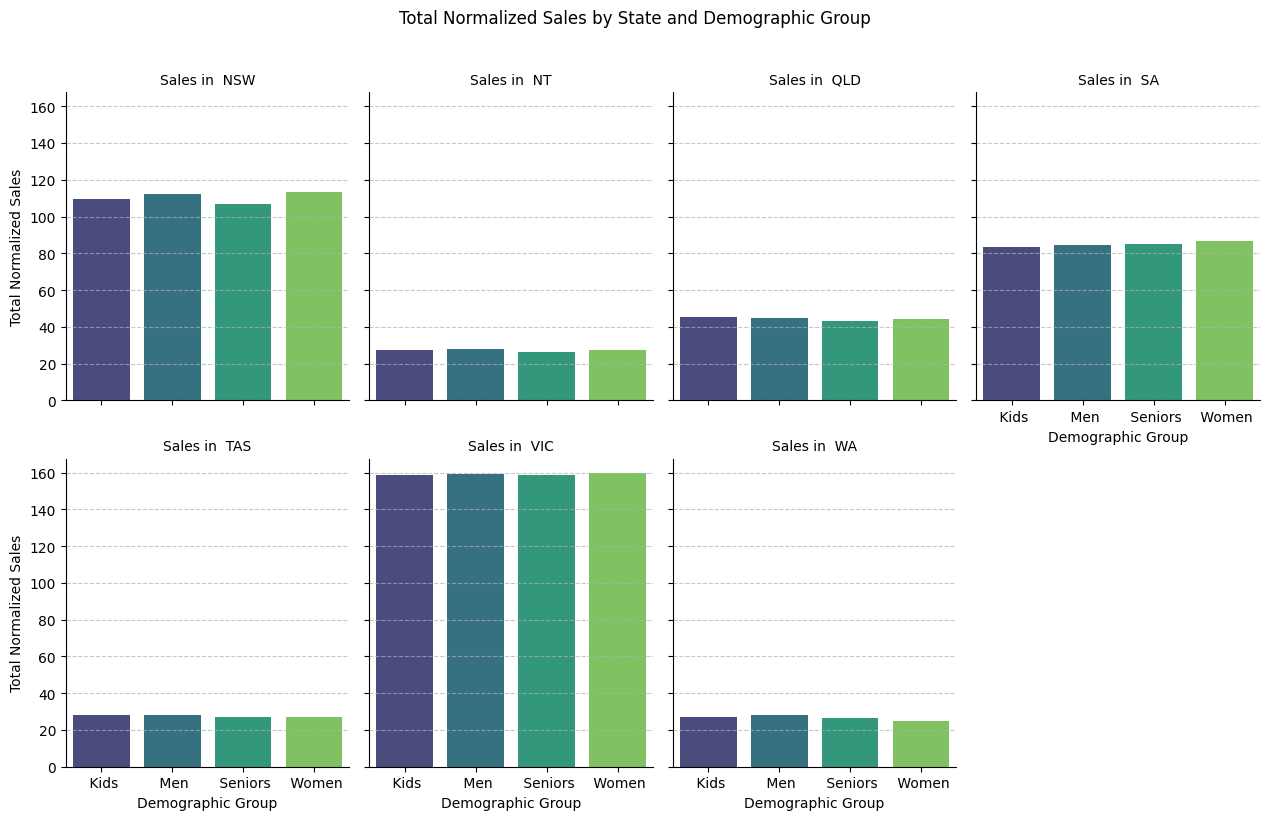

In [35]:


# Create a DataFrame for sales grouped by State and Group
sales_by_state_group = data.groupby(['State', 'Group'])['Sales'].sum().reset_index()

# Plotting State-wise sales for different demographic groups using sns.catplot
g = sns.catplot(
    data=sales_by_state_group,
    x='Group',
    y='Sales',
    col='State', # Facet by State
    kind='bar',
    palette='viridis',
    height=4, aspect=0.8,
    col_wrap=4 # Adjust for better layout if many states
)
g.set_axis_labels("Demographic Group", "Total Normalized Sales")
g.set_titles("Sales in {col_name}")
g.fig.suptitle('Total Normalized Sales by State and Demographic Group', y=1.02) # Set a main title for the figure
# Access individual axes to set grid
for ax in g.axes.flat:
    ax.grid(axis='y', linestyle='--', alpha=0.7)
g.tight_layout()
plt.show()

Next, let's visualize the group-wise sales analysis across various states. This will provide a different perspective on the same data, allowing us to see which groups perform best in which states.

/tmp/ipykernel_2226/800232607.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


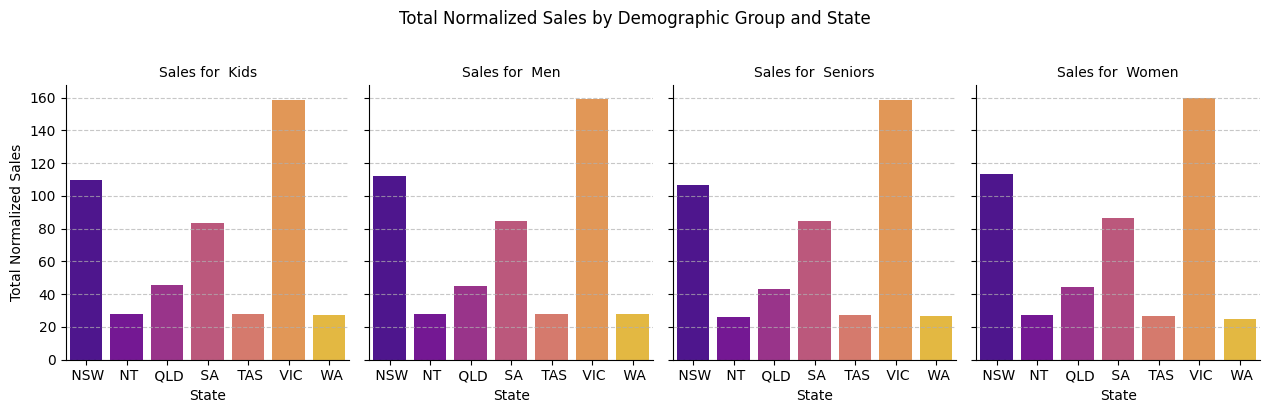

In [36]:
# Plotting Group-wise sales across various states using sns.catplot
g = sns.catplot(
    data=sales_by_state_group,
    x='State',
    y='Sales',
    col='Group', # Facet by Group
    kind='bar',
    palette='plasma',
    height=4, aspect=0.8,
    col_wrap=4 # Adjust as needed
)
g.set_axis_labels("State", "Total Normalized Sales")
g.set_titles("Sales for {col_name}")
g.fig.suptitle('Total Normalized Sales by Demographic Group and State', y=1.02)
for ax in g.axes.flat:
    ax.grid(axis='y', linestyle='--', alpha=0.7)
g.tight_layout()
plt.show()

Finally, let's analyze the sales distribution across different times of the day to identify peak and off-peak periods. This will help the S&M team with strategic planning.

/tmp/ipykernel_2226/2368885983.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Time', y='Sales', data=sales_by_time, palette='magma', ax=ax)
/tmp/ipykernel_2226/2368885983.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.barplot(x='Time', y='Sales', data=sales_by_time, palette='magma', ax=ax)


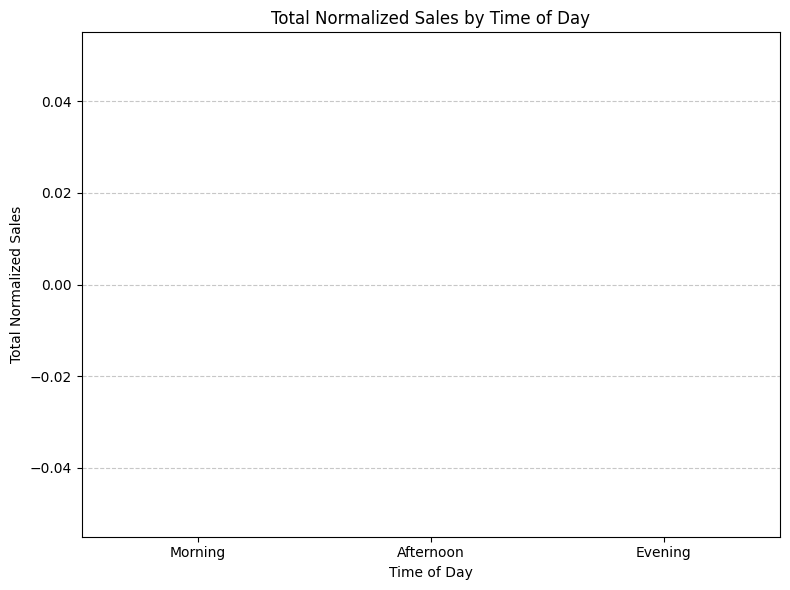

In [37]:
# Create a DataFrame for sales grouped by Time of Day
sales_by_time = data.groupby('Time')['Sales'].sum().reset_index()

# Define a specific order for the time periods for better visualization
time_order = ['Morning', 'Afternoon', 'Evening']
sales_by_time['Time'] = pd.Categorical(sales_by_time['Time'], categories=time_order, ordered=True)
sales_by_time = sales_by_time.sort_values('Time')

# Plotting Time-of-the-day analysis using Seaborn and explicit Axes methods
fig, ax = plt.subplots(figsize=(8, 6)) # Create figure and axes explicitly
sns.barplot(x='Time', y='Sales', data=sales_by_time, palette='magma', ax=ax)
ax.set_title('Total Normalized Sales by Time of Day')
ax.set_xlabel('Time of Day')
ax.set_ylabel('Total Normalized Sales')
ax.grid(axis='y', linestyle='--', alpha=0.7)
fig.tight_layout()
plt.show()